# Task Complexity: retraining on rubric ratings only

**What changed from the first clean run.** The first run had 20 rated records; the labels of the other 124 real records and of the 175
simulated records were estimates from a model fitted on those 20. Here the statistical propagation is gone: every real and every
simulated record has a rubric rating (`dataset/reference_ratings/`), the factor's label is the mean of its criteria rescaled to 0-1,
and the models are trained and tested on those ratings. The protocol is the same ([RETRAIN_PROTOCOL.md](../../RETRAIN_PROTOCOL.md),
amendment log); the success criteria were not touched.

**Who rated, plainly.** The 20 protocol ratings and the 299 new ones were all written by the assistant against the rubric. No person rated
anything, and the simulated students' ratings share an author with their data. A good result below shows that the models reproduce the
rubric as the assistant applies it. It is **not** human validation and not independent ground truth.

**Evaluation.** Primary: pooled over all 144 real records, each predicted by a model that never saw that student's group. Secondary: the
original 20 records only, for comparison with the first run. Simulated students are training only.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("../../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import retrain as R
from core import GROUPS, group_bootstrap, load, make_splits, md_table, metrics, paired_diff_bootstrap
from retrain_configs import CONFIGS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

cfg = CONFIGS["task_complexity_ref"]()
F = cfg.factor()
RES = F.results
d = load(F)
real, sim = d[d.source == "real"], d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
P20 = set(real[real.rating_source == "protocol-20"].record_id)
LABEL, ACT = cfg.label, cfg.activity
print(cfg.title, "| real", len(real), "all rated (protocol-20:", len(P20), "+ reference:", len(real) - len(P20), ") | simulated", len(sim), "training only, own ratings")

Task Complexity | real 144 all rated (protocol-20: 20 + reference: 124 ) | simulated 175 training only, own ratings


## 1. The labels

,n,mean,sd,p10,median,p90
records,,,,,,
"real, protocol-20",20,0.415,0.145,0.30,0.40,0.605
"real, reference",124,0.521,0.175,0.25,0.55,0.700
simulated,175,0.379,0.176,0.15,0.40,0.600


The 124 real records whose label was an estimate in the first run: estimate against rubric rating
  correlation 0.474 | mean abs difference 0.160


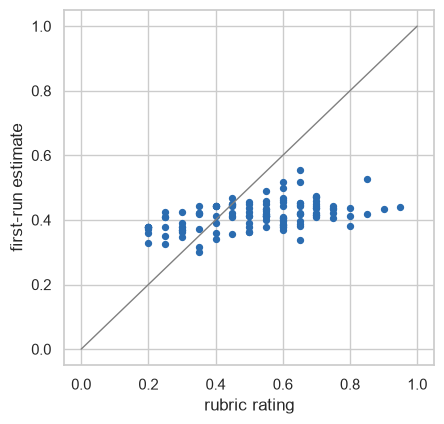

In [2]:
rows = []
for name, frame in (("real, protocol-20", real[real.rating_source == "protocol-20"]), ("real, reference", real[real.rating_source == "reference"]),
                    ("simulated", sim)):
    y = frame[LABEL].astype(float)
    rows.append({"records": name, "n": len(y), "mean": y.mean(), "sd": y.std(), "p10": y.quantile(.1), "median": y.median(), "p90": y.quantile(.9)})
display(pd.DataFrame(rows).set_index("records").round(3))
first = pd.read_csv(Path("../clean/dataset") / cfg.dataset_file, low_memory=False).set_index("record_id")
prop = first[(first.source == "real") & (first.label_source == "propagated")]
both = prop.label.astype(float).to_frame("propagated (first run)").join(real[LABEL].rename("rubric rating"))
print("The 124 real records whose label was an estimate in the first run: estimate against rubric rating")
print("  correlation %.3f | mean abs difference %.3f" % (both.corr().iloc[0, 1], (both.iloc[:, 0] - both.iloc[:, 1]).abs().mean()))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(both["rubric rating"], both["propagated (first run)"], s=18, c="#2b6cb0")
ax.plot([0, 1], [0, 1], color="grey", lw=1); ax.set_xlabel("rubric rating"); ax.set_ylabel("first-run estimate"); fig.tight_layout(); plt.show()

## 2. Splits and baselines (validation)

In [3]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source"]], on="record_id")
chk = role.groupby(["outer_test", "inner_val", "role"]).size().unstack(fill_value=0)
assert not ((role.role == "val") & (role.source == "synthetic")).any() and not ((role.role == "test") & (role.source == "synthetic")).any()
print("20 combinations; simulated rows are never in validation or test. Records per role (first rows):")
display(chk.head(8))
base = pd.read_csv(RES / "baseline_predictions.csv")
rows = []
for name, g in base.groupby("name"):
    m = metrics(g.y, g.pred)
    rows.append({"baseline": name, "MAE": m["MAE"], "pearson": m["pearson"], "spearman": m["spearman"], "bias": m["bias"]})
display(pd.DataFrame(rows).set_index("baseline").sort_values("MAE").round(3))

20 combinations; simulated rows are never in validation or test. Records per role (first rows):


role                  test  train  val
outer_test inner_val                  
A          B            71    220   28
           C            71    227   21
           D            71    232   16
           E            71    240    8
B          A            28    220   71
           C            28    270   21
           D            28    275   16
           E            28    283    8

,MAE,pearson,spearman,bias
baseline,,,,
ridge (5 proposal features),0.127,0.493,0.498,-0.004
"files involved (log, linear)",0.135,0.288,0.369,0.029
story points (linear),0.140,0.358,0.365,-0.004
subtasks (linear),0.141,0.317,0.283,-0.007
mean,0.148,-0.080,-0.082,-0.003
median,0.149,-0.067,-0.064,0.010


## 3. Preprocessing: variants and label sources (Ridge, validation, selection without bias)

In [4]:
tuned = pd.read_csv(RES / "tuning_predictions.csv")
settings = json.load(open(RES / "settings.json"))
rows = []
for (variant, lab, weight), g in tuned[tuned.model == "Ridge"].groupby(["variant", "lab", "weight"]):
    p, _ = R.bias_free(g)
    m = metrics(p.y, p.pred)
    rows.append({"variant": variant, "label source": lab, "weight": weight, "MAE": m["MAE"], "pearson": m["pearson"]})
pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True).round(3)

,variant,label source,weight,MAE,pearson
0,proposal 5 (log counts),rated + simulated (own ratings),0.3,0.131,0.487
1,proposal 5 (log counts),rated only,1.0,0.134,0.408
2,proposal 5 (log counts),rated + simulated (own ratings),1.0,0.134,0.520


## 4. Ridge, Random Forest and Gradient Boosting, tuned, compared without selection bias

In [5]:
choice, table, pools, picks = R.decide(cfg, tuned, base, d, RES)
table.round(3)

,model,variant,MAE,bias,pearson,spearman
0,Random Forest,proposal 5 (log counts),0.115,-0.042,0.619,0.612
1,Gradient Boosting,proposal 5 (log counts),0.116,-0.042,0.615,0.608
2,"Ridge (rated only, LOO alpha)",proposal,0.127,-0.004,0.493,0.498
3,Ridge,proposal 5 (log counts),0.133,-0.046,0.475,0.496


## 5. The rule for keeping a complex model

In [6]:
rule = choice["rule"]
print(f"best Ridge-type model : {rule['ridge']}  (MAE {choice['ridge_best']['MAE']:.3f})")
print(f"best tree model       : {rule['complex']}  (MAE {choice['complex_best']['MAE']:.3f})")
print(f"gain {rule['gain_mae']:+.3f} MAE, 95% interval {rule['ci'][0]:+.3f} to {rule['ci'][1]:+.3f}, better in {rule['folds_better']} of 5 folds")
chosen_name = choice["complex_best"]["model"] if rule["passes_1_3"] else choice["ridge_best"]["model"]
chosen_variant = choice["complex_best"]["variant"] if rule["passes_1_3"] else choice["ridge_best"]["variant"]
ridge_name, ridge_variant = choice["ridge_best"]["model"], choice["ridge_best"]["variant"]
print("model after rules 1-3:", chosen_name, "|", chosen_variant)

best Ridge-type model : Ridge (rated only, LOO alpha) | proposal  (MAE 0.127)
best tree model       : Random Forest | proposal 5 (log counts)  (MAE 0.115)
gain +0.012 MAE, 95% interval +0.004 to +0.035, better in 4 of 5 folds
model after rules 1-3: Random Forest | proposal 5 (log counts)


In [7]:
json.dump({**choice, "chosen": [chosen_name, chosen_variant]}, open(RES / "model_choice.json", "w"), indent=1, default=float)
print("model for the final test:", chosen_name, "|", chosen_variant)

model for the final test: Random Forest | proposal 5 (log counts)


## 6. Final test, scored once

In [8]:
final, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings)
final.to_csv(RES / "final_test_predictions_unguarded.csv", index=False)
MAIN = f"{chosen_name} | {chosen_variant}"

fold_info = pd.DataFrame({o: fits[(chosen_name, chosen_variant, o)][2] for o in GROUPS}).T
display(fold_info)
print(len(final[final.name == MAIN]), "test predictions from", len(GROUPS), "models, each made by a model that never saw that student")

,label_config,n_estimators,max_depth,min_samples_leaf,max_features
A,rated only (weight 1.0),300,6,1,1.0
B,rated only (weight 1.0),100,2,1,0.75
C,rated only (weight 1.0),100,6,2,1.0
D,rated + simulated (own ratings) (weight 0.3),100,2,12,0.75
E,rated only (weight 1.0),100,2,1,0.75


144 test predictions from 5 models, each made by a model that never saw that student


In [9]:
crit, m = R.criteria_table(cfg, final, MAIN, d)
crit.to_csv(RES / "final_test_criteria.csv", index=False)
print("PRIMARY: all %d real records" % len(final[final.name == MAIN]))
display(crit.round(3))
f20 = final[final.record_id.isin(P20)]
crit20, m20 = R.criteria_table(cfg, f20, MAIN, d)
crit20.to_csv(RES / "final_test_criteria_original20.csv", index=False)
print("SECONDARY: the original 20 records only (%d)" % len(f20[f20.name == MAIN]))
display(crit20.round(3))

PRIMARY: all 144 real records


,criterion,value,minimum,target,verdict,note
0,MAE / mean-guess MAE,0.751181,<= 0.8,<= 0.65,minimum met,"MAE 0.111, 95% interval 0.104-0.119"
1,Pearson and Spearman,0.618 / 0.607,>= 0.5 both,>= 0.7 / 0.7,minimum met,
2,Beats mean,gain +0.037 (+25%),interval of the gain excludes 0,>= 20% lower,target met,95% interval +0.004 to +0.055
3,Bias,-0.012788,within +-0.05,within +-0.03,target met,
4,Calibration slope,0.87819,0.5-1.5,0.8-1.2,target met,
5,Rubric bands within one,0.979167,>= 85%,>= 90%,target met,exact 51%


SECONDARY: the original 20 records only (20)


,criterion,value,minimum,target,verdict,note
0,MAE / mean-guess MAE,1.028254,<= 0.8,<= 0.65,NOT MET,"MAE 0.143, 95% interval 0.111-0.197"
1,Pearson and Spearman,0.456 / 0.366,>= 0.5 both,>= 0.7 / 0.7,NOT MET,
2,Beats mean,gain -0.004 (-3%),interval of the gain excludes 0,>= 20% lower,NOT MET,95% interval -0.034 to +0.018
3,Bias,0.104602,within +-0.05,within +-0.03,NOT MET,
4,Calibration slope,0.765034,0.5-1.5,0.8-1.2,minimum met,
5,Rubric bands within one,0.95,>= 85%,>= 90%,target met,exact 30%


,MAE,pearson,spearman,bias
model,,,,
Random Forest | proposal 5 (log counts),0.111,0.618,0.607,-0.013
"files involved (log, linear)",0.135,0.298,0.404,0.028
story points (linear),0.139,0.372,0.391,-0.004
subtasks (linear),0.140,0.335,0.294,-0.006
mean,0.147,-0.127,-0.098,-0.003
median,0.150,-0.109,-0.099,0.015


outer_test,A,B,C,D,E
n,71.000,28.000,21.000,16.000,8.000
MAE,0.109,0.114,0.127,0.097,0.101


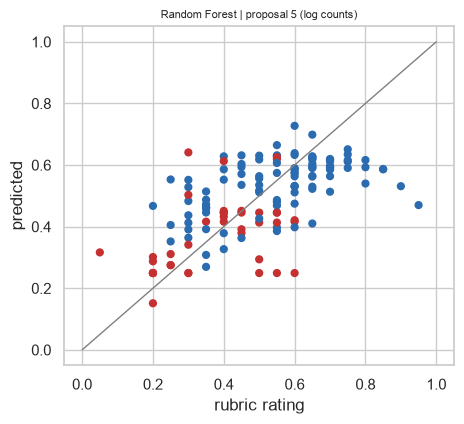

In [10]:
rows = []
for name, g in final.groupby("name"):
    mm = metrics(g.y, g.pred)
    rows.append({"model": name, "MAE": mm["MAE"], "pearson": mm["pearson"], "spearman": mm["spearman"], "bias": mm["bias"]})
display(pd.DataFrame(rows).set_index("model").sort_values("MAE").round(3))
pf = final[final.name == MAIN].assign(err=lambda x: (x.pred - x.y).abs())
display(pf.groupby("outer_test").agg(n=("err", "size"), MAE=("err", "mean")).round(3).T)
f = final[final.name == MAIN]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(f.y, f.pred, c=np.where(f.activity > 0, "#2b6cb0", "#c53030"), s=24)
ax.plot([0, 1], [0, 1], color="grey", lw=1)
ax.set_xlabel("rubric rating"); ax.set_ylabel("predicted"); ax.set_title(MAIN, fontsize=8)
fig.tight_layout(); plt.show()

## 7. Beside the first clean run and the uncleaned experiments

In [11]:
print("First clean run (labels: 20 ratings + estimates), criteria table:")
display(pd.read_csv(Path("../clean/training/results/final_test_criteria.csv")).round(3))
print("Uncleaned experiments (old features, 20 ratings), criteria table:")
display(pd.read_csv(Path("../training/results/final_test_criteria.csv")).round(3))

First clean run (labels: 20 ratings + estimates), criteria table:


,criterion,value,minimum,target,verdict,note
0,MAE / mean-guess MAE,0.9626006244134041,<= 0.8,<= 0.65,NOT MET,"MAE 0.119, 95% interval 0.059-0.195"
1,Pearson and Spearman,0.311 / 0.090,>= 0.5 both,>= 0.7 / 0.7,NOT MET,NaN
2,Beats mean,gain +0.005 (+4%),interval of the gain excludes 0,>= 20% lower,NOT MET,95% interval -0.027 to +0.034
3,Bias,0.034102748533423335,within +-0.05,within +-0.03,minimum met,NaN
4,Calibration slope,0.4048911465107742,0.5-1.5,0.8-1.2,NOT MET,NaN
5,Rubric bands within one,0.95,>= 85%,>= 90%,target met,exact 45%


Uncleaned experiments (old features, 20 ratings), criteria table:


,criterion,result,minimum (works),target,meets minimum,meets target
0,MAE / MAE of always predicting the mean,0.94 (0.116 / 0.124),<= 0.8,<= 0.65,False,False
1,Pearson,0.078,>= 0.5,>= 0.7,False,False
2,Spearman,0.003,>= 0.5,>= 0.7,False,False
3,Beats always predicting the mean,gain +0.008 (95% CI -0.014 to 0.027),interval excludes 0,and >= 20% lower MAE,False,False
4,Bias,+0.015,within +-0.05,within +-0.03,True,True
5,Calibration slope,0.18,0.5 - 1.5,0.8 - 1.2,False,False
6,Rubric bands within one,95%,>= 85%,>= 90%,True,True


## 8. Reading the results

_Reading of the results: written after the run._